# Phase 4 — Isolation Forest

Train an unsupervised Isolation Forest on all dense series, score it against the
injected eval set (`02_injection`), and read off a detection profile.

**Key methodological points discovered in this phase:**
- Features are **clipped** (99.9th pct) before training — raw z-scores reach
  1000+ on degenerate low-variance series and would dominate the trees.
- The headline metric is **recall at a fixed false-positive budget**, not
  PR-AUC: at ~1:150 imbalance PR-AUC is mechanically low and hard to read.
- Eval **negatives are restricted to clearly-normal weeks (|z| < 2)**, so the
  model isn't penalised for correctly flagging M5's unlabeled natural anomalies.
- The operating **threshold is set from an alert budget**, not an invented cost.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

from src.config import DATA_DIR
from src.data.aggregate import get_spark
from src.models.isolation_forest import (
    load_training_matrix, fit_clip_bounds, apply_clip,
    train_isolation_forest, score_eval_set, pr_auc_by_type,
    choose_threshold, FEATURE_COLS, CLIP_COLS,
)

spark = get_spark()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/01 13:43:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Training matrix

Load the feature matrix, keep fully-valid rows (drop first 52 weeks with no YoY,
etc.), bring to pandas. Unsupervised: the model trains on ALL dense series.

In [2]:
X = load_training_matrix(spark)
print("shape:", X.shape)
print("\nNaN:", X[FEATURE_COLS].isna().sum().sum(),
      " inf:", np.isinf(X[FEATURE_COLS]).sum().sum())

shape: (2186320, 8)

NaN: 0  inf: 0


## 2. Clip bounds

Learn clip bounds on training (99.9th pct) and apply them identically to train
and eval later. Only the three derived, unbounded features are clipped;
snap_days / cat_code / month are naturally bounded.

In [3]:
bounds = fit_clip_bounds(X)
for c, (lo, hi) in bounds.items():
    print(f"{c:14s} -> [{lo:.2f}, {hi:.2f}]")

print("\nafter clip (max):")
print(apply_clip(X, bounds)[CLIP_COLS].max())

sales_zscore   -> [-3.87, 9.67]
yoy_ratio      -> [0.00, 30.67]
wow_delta      -> [-1.00, 14.00]

after clip (max):
sales_zscore     9.667977
yoy_ratio       30.666667
wow_delta       14.000000
dtype: float64


## 3. Train

contamination is left at 'auto' on purpose — the operating threshold is chosen
later from the FP budget, not fixed here. max_samples=256 is the canonical IF
subsample, which also makes training fast on 2M+ rows.

In [4]:
import time
t0 = time.time()
model = train_isolation_forest(X, bounds)
print(f"trained in {time.time()-t0:.1f}s on {len(X):,} rows")

scores = model.score_samples(apply_clip(X, bounds)[FEATURE_COLS])
print("score pct:", np.percentile(scores, [0.1, 1, 5, 50, 95, 99]).round(3))

trained in 1.1s on 2,186,320 rows
score pct: [-0.692 -0.628 -0.567 -0.459 -0.411 -0.401]


## 4. Score the eval set

Rebuild the labelled eval set and bring it to pandas. Negatives are already
restricted to |z| < 2 inside `build_eval_set`. Scoring uses the TRAINING clip
bounds (never refit on eval) and negates score_samples so higher = more anomalous.

In [5]:
from src.evaluation.injection import build_eval_set, build_injection_pool

features = spark.read.parquet(str(DATA_DIR / "features.parquet"))
pool = build_injection_pool(features, n_series=3000)
eval_spark = build_eval_set(features, pool)

eval_cols = ["label", "anomaly_type", "severity_k"] + FEATURE_COLS
eval_pdf = eval_spark.select(*eval_cols).toPandas()
print(eval_pdf.groupby("label").size())

eval_scored = score_eval_set(model, eval_pdf, bounds)

label
0    414251
1    137589
dtype: int64
dropped 40,577 rows with NaN features (7.4%) before scoring


## 5. Detection profile — recall at fixed FP budget (primary metric)

The headline. Flag the top 5% / top 1% most anomalous weeks and measure, per
type and severity, what share of injected anomalies we catch. This speaks the
planner's language: *within the alert budget, how much do we catch?*

In [6]:
neg = eval_scored[eval_scored.label == 0]
thr95 = neg.anomaly_score.quantile(0.95)
thr99 = neg.anomaly_score.quantile(0.99)

print("=== recall @ 5% / 1% FP ===")
for atype in ["spike", "drop", "contextual", "level_shift"]:
    pt = eval_scored[(eval_scored.label==1) & (eval_scored.anomaly_type==atype)]
    if pt.severity_k.notna().any():
        for k in [2.0, 3.0, 4.0]:
            p = pt[pt.severity_k == k]
            print(f"{atype:12s} k={k}: recall@5%={np.mean(p.anomaly_score>=thr95):.1%}  "
                  f"recall@1%={np.mean(p.anomaly_score>=thr99):.1%}")
    else:
        print(f"{atype:12s}    : recall@5%={np.mean(pt.anomaly_score>=thr95):.1%}  "
              f"recall@1%={np.mean(pt.anomaly_score>=thr99):.1%}")

=== recall @ 5% / 1% FP ===
spike        k=2.0: recall@5%=26.4%  recall@1%=9.8%
spike        k=3.0: recall@5%=54.2%  recall@1%=23.1%
spike        k=4.0: recall@5%=80.7%  recall@1%=43.6%
drop         k=2.0: recall@5%=5.4%  recall@1%=0.2%
drop         k=3.0: recall@5%=12.9%  recall@1%=0.3%
drop         k=4.0: recall@5%=19.4%  recall@1%=0.9%
contextual      : recall@5%=12.5%  recall@1%=4.6%
level_shift  k=2.0: recall@5%=13.3%  recall@1%=3.8%
level_shift  k=3.0: recall@5%=19.4%  recall@1%=6.7%
level_shift  k=4.0: recall@5%=25.9%  recall@1%=10.2%


**Expected reading:** spikes strong and scaling with k (~81% at k=4); level
shifts capped ~26% even at k=4 (the rolling detector absorbs the plateau — the
quantified case for the autoencoder); contextual and drops weak (structural
limits of a tree-based IF on single-dimension and downward anomalies).

## 6. PR-AUC per type (secondary diagnostic)

Kept for completeness. Low absolute values are expected at ~1:150 imbalance —
this is why recall@FP is the headline, not this.

In [7]:
for atype, (ap, n) in pr_auc_by_type(eval_scored).items():
    print(f"{atype:14s} PR-AUC={ap:.3f}  (n_pos={n:,})")

spike          PR-AUC=0.349  (n_pos=13,940)
drop           PR-AUC=0.023  (n_pos=3,714)
contextual     PR-AUC=0.020  (n_pos=2,788)
level_shift    PR-AUC=0.403  (n_pos=108,780)


## 7. Operating threshold — from an alert budget

No real cost figures exist (public dataset), so the threshold is expressed as an
**alert budget**: flag ~5% of normal weeks. The threshold is a fixed score value
(a model artifact) — in production there are no negatives to re-quantile against.

In [8]:
res = choose_threshold(eval_scored, fp_budget=0.05)
print(f"threshold (score): {res['threshold']:.4f}")
print("recall by type:", {k: f'{v:.1%}' for k, v in res['recall_by_type'].items()})

n_series_total = 15509
print(f"\n~{n_series_total * res['fp_budget']:.0f} alerts/week on the dense pool")

threshold (score): 0.5505
recall by type: {'spike': '53.1%', 'drop': '9.8%', 'contextual': '12.5%', 'level_shift': '19.5%'}

~775 alerts/week on the dense pool


## 8. Sensitivity — recall vs alert budget

The trade-off made visible (the FVA-style honesty check): no magic threshold,
just a chosen point on an exposed curve.

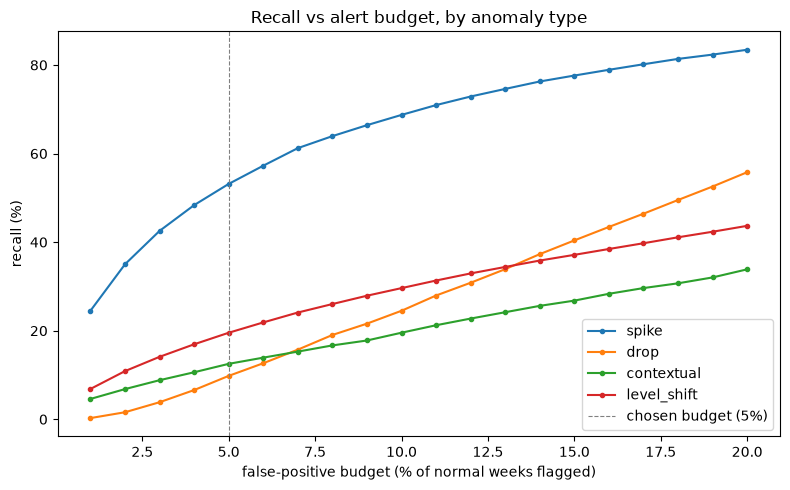

In [9]:
budgets = np.linspace(0.01, 0.20, 20)
fig, ax = plt.subplots(figsize=(8, 5))

for atype in ["spike", "drop", "contextual", "level_shift"]:
    pos = eval_scored[(eval_scored.label==1) & (eval_scored.anomaly_type==atype)]
    recalls = []
    for b in budgets:
        thr = neg.anomaly_score.quantile(1 - b)
        recalls.append((pos.anomaly_score >= thr).mean())
    ax.plot(budgets*100, np.array(recalls)*100, marker="o", ms=3, label=atype)

ax.axvline(5, color="gray", ls="--", lw=0.8, label="chosen budget (5%)")
ax.set_xlabel("false-positive budget (% of normal weeks flagged)")
ax.set_ylabel("recall (%)")
ax.set_title("Recall vs alert budget, by anomaly type")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

The Isolation Forest is a strong detector of **upward point shocks**, mediocre
on **sustained regime changes** and **contextual/seasonal** anomalies, and weak
on **downward shocks**. A clear, defensible profile that defines the brief for
the LSTM autoencoder (Phase 6): cover the sequence-shaped and context-dependent
blind spots. Model artifacts to persist: the IF model, the clip `bounds`, and
the operating `threshold` (next: MLflow tracking + export).

In [10]:
from src.models.isolation_forest import log_run

run_id = log_run(model, bounds, res, eval_scored)
print("logged run:", run_id)

/Users/alex/Projects/anomaly-detection-sc/.venv/lib/python3.11/site-packages/mlflow/utils/requirements_utils.py:20: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources  # noqa: TID251


logged run: feb81adf298e474a8ecc2676eb3de709


/Users/alex/Projects/anomaly-detection-sc/.venv/lib/python3.11/site-packages/_distutils_hack/__init__.py:30: UserWarning: Setuptools is replacing distutils. Support for replacing an already imported distutils is deprecated. In the future, this condition will fail. Register concerns at https://github.com/pypa/setuptools/issues/new?template=distutils-deprecation.yml
  warnings.warn(


## Model Exportation

In [12]:
import numpy as np
from src.models.isolation_forest import export_model, load_bundle, score_rows

out = export_model(model, bounds, res)
print("exported to:", out)

m2, b2, thr2, cols2 = load_bundle()
print("threshold:", thr2["threshold"])

# Mêmes lignes : on re-score eval_scored et on compare à son anomaly_score stocké
sample = eval_scored.head(1000)
check = score_rows(sample, m2, b2, thr2["threshold"], cols2)

print("scores identiques:",
      np.allclose(check["anomaly_score"].values, sample["anomaly_score"].values))
print("taux d'anomalies flaggées:", check["is_anomaly"].mean())

exported to: /Users/alex/Projects/anomaly-detection-sc/models/isolation_forest
threshold: 0.5504726219255254
scores identiques: True
taux d'anomalies flaggées: 0.211
